# Estimación de costo del proyecto NIBEL con COCOMO
**Autor:** DAIT - David Alex Inofuente Trujillo
**Proyecto:** NIBEL - Tienda web de chompas de lana y alpaca (FastAPI + PostgreSQL + HTML/Tailwind)
**Repositorio:** https://github.com/alexinofuente22-lang/nibel-ecommerce

Este cuaderno hace lo siguiente:
1. Descarga el código del proyecto y cuenta sus líneas: físicas, vacías, comentarios y código.
2. Calcula el **COCOMO Básico** en sus tres modos: orgánico, semi-acoplado y empotrado.
3. Calcula el **COCOMO Intermedio** con los 15 factores de costo.
4. Estima el **costo en soles** con el sueldo de un desarrollador en Perú.
5. Compara la estimación con el tiempo real de desarrollo.

> Ejecuta las celdas en orden con *Entorno de ejecución → Ejecutar todas*.

## 1. Obtener el código fuente (DAIT)

In [1]:
# DAIT: se descarga el repositorio público de GitHub.
# Si no hay internet o el repo no está disponible, se usan los conteos medidos el 25/10/2026.
import os, subprocess

REPO = "https://github.com/alexinofuente22-lang/nibel-ecommerce.git"
CARPETA = "nibel"

if not os.path.isdir(CARPETA):
    r = subprocess.run(["git", "clone", "--depth", "1", REPO, CARPETA], capture_output=True, text=True)
    print(r.stdout or r.stderr)

CODIGO_DISPONIBLE = os.path.isdir(CARPETA)
print("Código descargado:", CODIGO_DISPONIBLE)

## 2. Conteo de líneas de código (DAIT)
Se cuentan solo los archivos escritos a mano. `requirements.txt` queda fuera porque lo genera `pip freeze`, y también el logo SVG.

- **Líneas físicas:** todas las líneas del archivo.
- **Líneas vacías:** líneas en blanco.
- **Comentarios:** líneas que solo tienen comentarios (`#`, `//`, `/* */`, `<!-- -->`, docstrings de una línea).
- **Líneas de código (SLOC):** físicas − vacías − comentarios. **Este es el valor que usa COCOMO.**

In [2]:
import pandas as pd

ARCHIVOS = ["main.py", "auth.py", "database.py", "models.py", "schemas.py",
            "index.html", "admin.html", "render.yaml", "vercel.json"]

# DAIT: conteos medidos sobre la versión limpia del proyecto (25/10/2026)
CONTEO_MEDIDO = [
    ("main.py", 214, 46, 29), ("auth.py", 35, 9, 10), ("database.py", 36, 9, 9),
    ("models.py", 36, 8, 8), ("schemas.py", 49, 14, 8), ("index.html", 461, 48, 41),
    ("admin.html", 326, 36, 25), ("render.yaml", 7, 0, 1), ("vercel.json", 15, 0, 0),
]


def contar_lineas(nombre, texto):
    """DAIT: clasifica cada línea en vacía, comentario o código."""
    lineas = texto.replace("\r\n", "\n").split("\n")
    if lineas and lineas[-1] == "":
        lineas = lineas[:-1]
    vacias = comentarios = 0
    fin_bloque = None
    ext = nombre.rsplit(".", 1)[-1]
    for linea in lineas:
        t = linea.strip()
        if not t:
            vacias += 1
            continue
        if fin_bloque:
            comentarios += 1
            if fin_bloque in t:
                fin_bloque = None
            continue
        if ext in ("py", "yaml") and t.startswith("#"):
            comentarios += 1
        elif ext == "py" and t.startswith('"""') and t.endswith('"""') and len(t) > 5:
            comentarios += 1
        elif ext == "html" and t.startswith("<!--"):
            comentarios += 1
            fin_bloque = None if "-->" in t else "-->"
        elif ext == "html" and t.startswith("/*"):
            comentarios += 1
            fin_bloque = None if "*/" in t else "*/"
        elif ext == "html" and t.startswith("//"):
            comentarios += 1
    return len(lineas), vacias, comentarios


# DAIT: se usa el repositorio solo si ya tiene la versión limpia (con cabeceras DAIT)
def version_limpia(carpeta):
    try:
        with open(os.path.join(carpeta, "main.py"), encoding="utf-8") as f:
            return "DAIT" in f.read()
    except OSError:
        return False


filas = []
if CODIGO_DISPONIBLE and version_limpia(CARPETA) and all(os.path.exists(os.path.join(CARPETA, a)) for a in ARCHIVOS):
    for a in ARCHIVOS:
        with open(os.path.join(CARPETA, a), encoding="utf-8") as f:
            filas.append((a, *contar_lineas(a, f.read())))
    origen = "repositorio de GitHub"
else:
    filas = CONTEO_MEDIDO
    origen = "conteo medido sobre la versión limpia (25/10/2026)"

df = pd.DataFrame(filas, columns=["Archivo", "Físicas", "Vacías", "Comentarios"])
df["Código (SLOC)"] = df["Físicas"] - df["Vacías"] - df["Comentarios"]
df["Lenguaje"] = df["Archivo"].map(lambda a: {"py": "Python", "html": "HTML/CSS/JS",
                                              "yaml": "YAML", "json": "JSON"}[a.rsplit(".", 1)[-1]])
df.loc["Total"] = ["TOTAL", *df[["Físicas", "Vacías", "Comentarios", "Código (SLOC)"]].sum(), ""]

print("Origen de los datos:", origen)
display(df)

SLOC = int(df.loc["Total", "Código (SLOC)"])
KLOC = SLOC / 1000
print(f"\nSLOC = {SLOC}  ->  KLOC = {KLOC:.3f}")

Origen de los datos: repositorio de GitHub


,Archivo,Físicas,Vacías,Comentarios,Código (SLOC),Lenguaje
0,main.py,214,46,29,139,Python
1,auth.py,35,9,10,16,Python
2,database.py,36,9,9,18,Python
3,models.py,36,8,8,20,Python
4,schemas.py,49,14,8,27,Python
5,index.html,461,48,41,372,HTML/CSS/JS
6,admin.html,326,36,25,265,HTML/CSS/JS
7,render.yaml,7,0,1,6,YAML
8,vercel.json,15,0,0,15,JSON
Total,TOTAL,1179,170,131,878,



SLOC = 878  ->  KLOC = 0.878


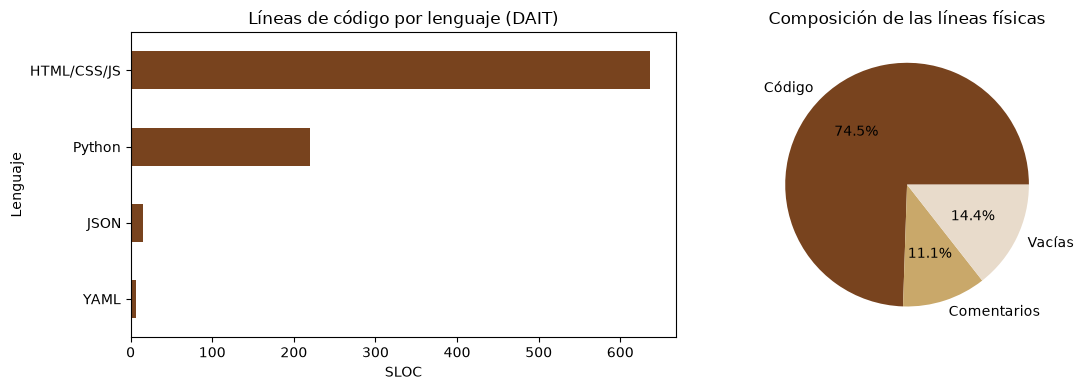

In [3]:
# DAIT: distribución de líneas por lenguaje
import matplotlib.pyplot as plt

por_lenguaje = df.drop("Total").groupby("Lenguaje")["Código (SLOC)"].sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_lenguaje.plot.barh(ax=ax[0], color="#78431e")
ax[0].set_title("Líneas de código por lenguaje (DAIT)")
ax[0].set_xlabel("SLOC")
tot = df.loc["Total"]
ax[1].pie([tot["Código (SLOC)"], tot["Comentarios"], tot["Vacías"]],
          labels=["Código", "Comentarios", "Vacías"], autopct="%1.1f%%",
          colors=["#78431e", "#C9A86A", "#e8dbcb"])
ax[1].set_title("Composición de las líneas físicas")
plt.tight_layout()
plt.show()

## 3. COCOMO Básico (DAIT)
Fórmulas de Boehm (1981):

$$E = a \cdot (KLOC)^{b} \quad [\text{personas-mes}] \qquad D = c \cdot E^{d} \quad [\text{meses}] \qquad P = E / D \quad [\text{personas}]$$

| Modo | a | b | c | d | Cuándo se usa |
|---|---|---|---|---|---|
| Orgánico | 2.4 | 1.05 | 2.5 | 0.38 | Proyectos pequeños, equipo con experiencia, requisitos flexibles |
| Semi-acoplado | 3.0 | 1.12 | 2.5 | 0.35 | Tamaño y complejidad medios |
| Empotrado | 3.6 | 1.20 | 2.5 | 0.32 | Restricciones fuertes de hardware o tiempo real |

**NIBEL es un proyecto orgánico:** es pequeño (menos de 50 KLOC), lo hace una sola persona, usa tecnología conocida (Python/JS) y no tiene restricciones rígidas.

In [4]:
MODOS = {
    "Orgánico":      (2.4, 1.05, 2.5, 0.38),
    "Semi-acoplado": (3.0, 1.12, 2.5, 0.35),
    "Empotrado":     (3.6, 1.20, 2.5, 0.32),
}


def cocomo_basico(kloc, a, b, c, d):
    """DAIT: devuelve esfuerzo (PM), duración (meses) y personas."""
    esfuerzo = a * kloc ** b
    duracion = c * esfuerzo ** d
    return esfuerzo, duracion, esfuerzo / duracion


basico = pd.DataFrame(
    [(m, *cocomo_basico(KLOC, *p)) for m, p in MODOS.items()],
    columns=["Modo", "Esfuerzo (PM)", "Duración (meses)", "Personas"],
).set_index("Modo")
display(basico.round(2))

E_BAS, D_BAS, P_BAS = basico.loc["Orgánico"]
print(f"Modo elegido (Orgánico): E = {E_BAS:.2f} PM, D = {D_BAS:.2f} meses, P = {P_BAS:.2f} personas")

,Esfuerzo (PM),Duración (meses),Personas
Modo,,,
Orgánico,2.09,3.31,0.63
Semi-acoplado,2.59,3.49,0.74
Empotrado,3.08,3.58,0.86


Modo elegido (Orgánico): E = 2.09 PM, D = 3.31 meses, P = 0.63 personas


## 4. COCOMO Intermedio (DAIT)
Agrega un **Factor de Ajuste del Esfuerzo (EAF)**, que es el producto de 15 multiplicadores de costo.
En el modo orgánico intermedio: $E = 3.2 \cdot (KLOC)^{1.05} \cdot EAF$.

Valoración de cada factor para NIBEL:

In [5]:
# DAIT: (factor, descripción, nivel elegido, multiplicador, justificación)
FACTORES = [
    ("RELY", "Fiabilidad requerida",               "Nominal", 1.00, "Una falla causa pérdidas recuperables (pedido por WhatsApp)"),
    ("DATA", "Tamaño de la base de datos",         "Bajo",    0.94, "Solo 2 tablas (productos, usuarios) con pocos registros"),
    ("CPLX", "Complejidad del producto",           "Bajo",    0.85, "CRUD sencillo, sin algoritmos complejos"),
    ("TIME", "Restricción de tiempo de ejecución", "Nominal", 1.00, "Sin requisitos de rendimiento críticos"),
    ("STOR", "Restricción de memoria",             "Nominal", 1.00, "Hosting en la nube sin límites relevantes"),
    ("VIRT", "Volatilidad de la plataforma",       "Bajo",    0.87, "Render y Vercel son plataformas estables"),
    ("TURN", "Tiempo de respuesta del entorno",    "Bajo",    0.87, "Despliegue automático con cada push a Git"),
    ("ACAP", "Capacidad del analista",             "Nominal", 1.00, "Estudiante con buen dominio del negocio"),
    ("AEXP", "Experiencia en la aplicación",       "Bajo",    1.13, "Primer e-commerce desarrollado"),
    ("PCAP", "Capacidad del programador",          "Nominal", 1.00, "Nivel de programador junior/estudiante"),
    ("VEXP", "Experiencia en la plataforma",       "Bajo",    1.10, "Primer uso de Render, Vercel e ImgBB"),
    ("LEXP", "Experiencia en el lenguaje",         "Nominal", 1.00, "Python y JavaScript vistos en la carrera"),
    ("MODP", "Prácticas modernas de programación", "Alto",    0.91, "ORM, framework FastAPI, control de versiones Git"),
    ("TOOL", "Uso de herramientas de software",    "Alto",    0.91, "VS Code, Git/GitHub, Tailwind, asistentes de código"),
    ("SCED", "Restricción del cronograma",         "Nominal", 1.00, "Plazo académico normal"),
]
factores = pd.DataFrame(FACTORES, columns=["Código", "Factor", "Nivel", "Multiplicador", "Justificación"])
display(factores)

import math
EAF = math.prod(factores["Multiplicador"])
E_INT = 3.2 * KLOC ** 1.05 * EAF
D_INT = 2.5 * E_INT ** 0.38
P_INT = E_INT / D_INT
print(f"EAF = {EAF:.4f}")
print(f"COCOMO Intermedio: E = {E_INT:.2f} PM, D = {D_INT:.2f} meses, P = {P_INT:.2f} personas")

,Código,Factor,Nivel,Multiplicador,Justificación
0,RELY,Fiabilidad requerida,Nominal,1.00,Una falla causa pérdidas recuperables (pedido ...
1,DATA,Tamaño de la base de datos,Bajo,0.94,"Solo 2 tablas (productos, usuarios) con pocos ..."
2,CPLX,Complejidad del producto,Bajo,0.85,"CRUD sencillo, sin algoritmos complejos"
3,TIME,Restricción de tiempo de ejecución,Nominal,1.00,Sin requisitos de rendimiento críticos
4,STOR,Restricción de memoria,Nominal,1.00,Hosting en la nube sin límites relevantes
5,VIRT,Volatilidad de la plataforma,Bajo,0.87,Render y Vercel son plataformas estables
6,TURN,Tiempo de respuesta del entorno,Bajo,0.87,Despliegue automático con cada push a Git
7,ACAP,Capacidad del analista,Nominal,1.00,Estudiante con buen dominio del negocio
8,AEXP,Experiencia en la aplicación,Bajo,1.13,Primer e-commerce desarrollado
9,PCAP,Capacidad del programador,Nominal,1.00,Nivel de programador junior/estudiante


EAF = 0.6225
COCOMO Intermedio: E = 1.74 PM, D = 3.08 meses, P = 0.56 personas


## 5. Costo del proyecto en soles (DAIT)
**Sueldo de referencia de un desarrollador en Perú (octubre 2026):**
- Indeed Perú: promedio de **S/ 2,544** al mes para desarrollador de software (todos los niveles).
- Coderhouse: **S/ 4,500 a S/ 5,500** al mes para desarrollador junior (estimación comercial).

**Escenario base: S/ 4,000 al mes**, un punto intermedio entre ambas fuentes para un desarrollador web junior.

Además del sueldo bruto se calcula el **costo para el empleador** (régimen general), que agrega aproximadamente:
2 gratificaciones + 1 CTS + EsSalud 9% ≈ **factor 1.36** sobre el sueldo.

In [6]:
SUELDO_BASE = 4000          # DAIT: S/ por mes, escenario base
FACTOR_EMPLEADOR = (12 + 2 + 1 + 0.09 * 14) / 12   # sueldos + gratificaciones + CTS + EsSalud

ESCENARIOS = {"Promedio Indeed (S/ 2,544)": 2544,
              "Base DAIT (S/ 4,000)": SUELDO_BASE,
              "Junior Coderhouse (S/ 5,000)": 5000}

filas = []
for nombre, sueldo in ESCENARIOS.items():
    for modelo, esfuerzo in [("Básico", E_BAS), ("Intermedio", E_INT)]:
        filas.append((nombre, modelo, round(esfuerzo, 2), sueldo * esfuerzo, sueldo * esfuerzo * FACTOR_EMPLEADOR))
costos = pd.DataFrame(filas, columns=["Escenario", "COCOMO", "Esfuerzo (PM)", "Costo sueldo (S/)", "Costo empleador (S/)"])
pd.options.display.float_format = "{:,.2f}".format
display(costos)

COSTO_BAS = E_BAS * SUELDO_BASE
COSTO_INT = E_INT * SUELDO_BASE
print(f"Factor empleador = {FACTOR_EMPLEADOR:.3f}")
print(f"Costo base (Básico)     = S/ {COSTO_BAS:,.2f}")
print(f"Costo base (Intermedio) = S/ {COSTO_INT:,.2f}")
print(f"Productividad (Básico)  = {SLOC / E_BAS:,.0f} líneas por persona-mes")

,Escenario,COCOMO,Esfuerzo (PM),Costo sueldo (S/),Costo empleador (S/)
0,"Promedio Indeed (S/ 2,544)",Básico,2.09,"5,325.96","7,216.67"
1,"Promedio Indeed (S/ 2,544)",Intermedio,1.74,"4,420.54","5,989.83"
2,"Base DAIT (S/ 4,000)",Básico,2.09,"8,374.14","11,346.97"
3,"Base DAIT (S/ 4,000)",Intermedio,1.74,"6,950.54","9,417.98"
4,"Junior Coderhouse (S/ 5,000)",Básico,2.09,"10,467.68","14,183.71"
5,"Junior Coderhouse (S/ 5,000)",Intermedio,1.74,"8,688.17","11,772.47"


Factor empleador = 1.355
Costo base (Básico)     = S/ 8,374.14
Costo base (Intermedio) = S/ 6,950.54
Productividad (Básico)  = 419 líneas por persona-mes


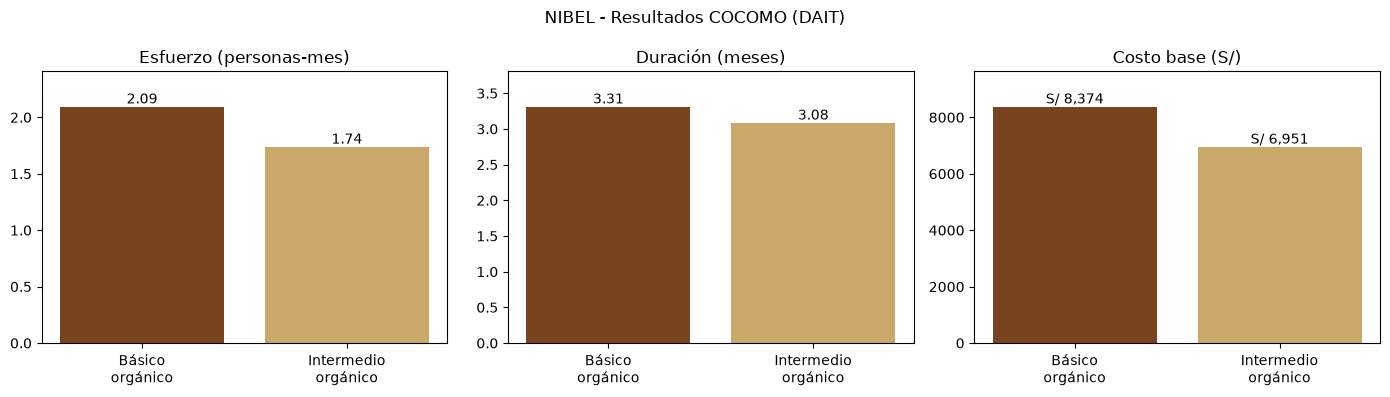

In [7]:
# DAIT: comparación gráfica de los modelos
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
etiquetas = ["Básico\norgánico", "Intermedio\norgánico"]
colores = ["#78431e", "#C9A86A"]
for i, (titulo, valores, formato) in enumerate([
    ("Esfuerzo (personas-mes)", [E_BAS, E_INT], "{:.2f}"),
    ("Duración (meses)", [D_BAS, D_INT], "{:.2f}"),
    ("Costo base (S/)", [COSTO_BAS, COSTO_INT], "S/ {:,.0f}"),
]):
    barras = ax[i].bar(etiquetas, valores, color=colores)
    ax[i].bar_label(barras, labels=[formato.format(v) for v in valores])
    ax[i].set_title(titulo)
    ax[i].margins(y=0.15)
fig.suptitle("NIBEL - Resultados COCOMO (DAIT)")
plt.tight_layout()
plt.show()

## 6. Escenario alternativo (DAIT)
Supone que una **empresa de software** encarga el sistema a un **desarrollador semi-senior (S/ 6,000 al mes)** y usa el **modo semi-acoplado**, porque la empresa exigiría más formalidad: integración con ImgBB y WhatsApp, despliegue en dos plataformas y requisitos firmados.

In [8]:
SUELDO_ALT = 6000
E_ALT, D_ALT, P_ALT = basico.loc["Semi-acoplado"]
escenarios = pd.DataFrame({
    "Escenario base": ["Orgánico", f"S/ {SUELDO_BASE:,}", E_BAS, D_BAS, P_BAS, E_BAS * SUELDO_BASE, E_BAS * SUELDO_BASE * FACTOR_EMPLEADOR],
    "Escenario alternativo": ["Semi-acoplado", f"S/ {SUELDO_ALT:,}", E_ALT, D_ALT, P_ALT, E_ALT * SUELDO_ALT, E_ALT * SUELDO_ALT * FACTOR_EMPLEADOR],
}, index=["Modo", "Sueldo mensual", "Esfuerzo (PM)", "Duración (meses)", "Personas", "Costo sueldo (S/)", "Costo laboral (S/)"])
display(escenarios)
print(f"El escenario alternativo cuesta {E_ALT * SUELDO_ALT / (E_BAS * SUELDO_BASE) - 1:.0%} más que el base.")

,Escenario base,Escenario alternativo
Modo,Orgánico,Semi-acoplado
Sueldo mensual,"S/ 4,000","S/ 6,000"
Esfuerzo (PM),2.09,2.59
Duración (meses),3.31,3.49
Personas,0.63,0.74
Costo sueldo (S/),"8,374.14","15,559.17"
Costo laboral (S/),"11,346.97","21,082.67"


El escenario alternativo cuesta 86% más que el base.


## 7. Comparación con el desarrollo real (DAIT)
Según el historial de Git, el proyecto se construyó entre el **02/09/2026 y el 06/09/2026**, con 17 commits en 3 días de trabajo.

In [9]:
DIAS_REALES = 3                 # DAIT: días con commits (02, 05 y 06 de septiembre de 2026)
HORAS_POR_DIA = 8
HORAS_MES = 160

horas_reales = DIAS_REALES * HORAS_POR_DIA
pm_real = horas_reales / HORAS_MES
comparacion = pd.DataFrame({
    "Esfuerzo (PM)": [E_BAS, E_INT, pm_real],
    "Horas-persona": [E_BAS * HORAS_MES, E_INT * HORAS_MES, horas_reales],
    "Costo (S/)": [COSTO_BAS, COSTO_INT, pm_real * SUELDO_BASE],
}, index=["COCOMO Básico", "COCOMO Intermedio", "Real (aprox.)"])
display(comparacion)
print(f"COCOMO Básico estima {E_BAS / pm_real:.1f} veces el esfuerzo real aproximado.")

,Esfuerzo (PM),Horas-persona,Costo (S/)
COCOMO Básico,2.09,334.97,"8,374.14"
COCOMO Intermedio,1.74,278.02,"6,950.54"
Real (aprox.),0.15,24.00,600.00


COCOMO Básico estima 14.0 veces el esfuerzo real aproximado.


### Interpretación
- COCOMO se calibró en 1981 con proyectos industriales que incluían análisis, diseño, documentación, pruebas formales y gestión. Aplicado a un proyecto de menos de 1 KLOC, **sobreestima** el esfuerzo.
- El desarrollo real fue mucho más rápido gracias a frameworks (FastAPI, SQLAlchemy, Tailwind), servicios en la nube (Render, Vercel, ImgBB) y herramientas modernas. Ninguno de ellos existía cuando se definió el modelo.
- Aun así, el valor de COCOMO es una **cotización razonable** de lo que costaría encargar este sistema a un tercero que siga todo el ciclo de vida del software (requisitos, diseño, pruebas, documentación y despliegue).

*Elaborado por DAIT - David Alex Inofuente Trujillo.*